<a href="https://colab.research.google.com/github/LunaGar1/Practica4-Vision-e-IA/blob/main/Reto1_P4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reto 1 – Clasificación de 3 escenas (coast / forest / highway)
**Machine Learning vs Deep Learning (CNN, ResNet50) vs Transformer (ViT)**

Los modelos de Deep Learning y Transformer comparten **exactamente la misma partición** train / val / test (estratificada, semilla fija).
La selección de modelos se hace con **validación**; el **test** solo se usa para reportar.
La comparación con **Machine Learning** se hace contra los resultados de la práctica anterior

## 0. Configuración

In [ ]:
!pip -q install timm

In [ ]:
import os, random, time, json, copy, gc, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
from google.colab import drive
warnings.filterwarnings('ignore')
drive.mount('/content/drive')

SEED = 42
random.seed(SEED); np.random.seed(SEED)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
tf.keras.utils.set_random_seed(SEED)
tf.get_logger().setLevel('ERROR')   # oculta avisos de retracing
for g in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(g, True)   # para convivir con PyTorch

import torch
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo PyTorch:', device, '| GPUs TF:', tf.config.list_physical_devices('GPU'))

BASE_PATH = '/content/drive/MyDrive/VisionComputadorIA/'
FOLDER    = '3scenes/'
CLASSES   = ['coast', 'forest', 'highway']
OUT_DIR   = BASE_PATH + 'Reto1_evidencia/'
os.makedirs(OUT_DIR + 'figs', exist_ok=True)
os.makedirs(OUT_DIR + 'modelos', exist_ok=True)

Mounted at /content/drive
Dispositivo PyTorch: cpu | GPUs TF: []


## 1. Datos y partición común
Se ordenan los archivos (`sorted`) para que el orden sea reproducible, y se usa partición estratificada:
**60 % train / 15 % validación / 25 % test**

In [ ]:
from sklearn.model_selection import train_test_split

paths, y = [], []
for ci, c in enumerate(CLASSES):
    d = os.path.join(BASE_PATH + FOLDER, c)
    for f in sorted(os.listdir(d)):
        if f.lower().endswith('.jpg'):
            paths.append(os.path.join(d, f)); y.append(ci)
paths = np.array(paths); y = np.array(y)

idx = np.arange(len(y))
idx_trainval, idx_test = train_test_split(idx, test_size=0.25, stratify=y, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.20, stratify=y[idx_trainval], random_state=SEED)
y_test = y[idx_test]

print('Total:', len(y), '| train:', len(idx_train), '| val:', len(idx_val), '| test:', len(idx_test))
print(pd.Series(y).map(dict(enumerate(CLASSES))).value_counts())

Total: 958 | train: 574 | val: 144 | test: 240
coast      360
forest     328
highway    270
Name: count, dtype: int64


## 2. Utilidades de evaluación (comunes a todos los modelos)

In [ ]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             classification_report, cohen_kappa_score, matthews_corrcoef,
                             roc_auc_score, roc_curve, auc)
from sklearn.preprocessing import label_binarize

RESULTS = {}   # nombre -> dict con predicciones, probabilidades, historia y métricas

def register(name, proba, y_pred=None, train_time=None, n_params=None, infer_ms=None, history=None, group=''):
    y_pred = proba.argmax(1) if y_pred is None else y_pred
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    try:
        auc_macro = roc_auc_score(y_test, proba, multi_class='ovr', average='macro')
    except Exception:
        auc_macro = np.nan
    RESULTS[name] = dict(
        group=group, y_pred=np.asarray(y_pred), proba=proba, history=history,
        metrics={'Accuracy': accuracy_score(y_test, y_pred), 'Precision_macro': p, 'Recall_macro': r,
                 'F1_macro': f, 'Kappa': cohen_kappa_score(y_test, y_pred),
                 'MCC': matthews_corrcoef(y_test, y_pred), 'AUC_macro': auc_macro,
                 'Params': n_params, 'Train_s': train_time, 'Infer_ms_img': infer_ms})
    print(f"[{name}]  acc={accuracy_score(y_test, y_pred):.4f}  F1-macro={f:.4f}")

def save_fig(name):
    plt.tight_layout()
    plt.savefig(OUT_DIR + 'figs/' + name + '.png', dpi=150, bbox_inches='tight')
    plt.show()

### Referencia: resultados de Machine Learning de la práctica anterior
Valores tomados del notebook de ML (SVC, RandomForest, MLP, etc. con características RGB/HSV/Haralick).

In [ ]:
REF_ML = {
    'ML previo: MLP + HSV+Haralick (mejor)': 0.9292,
    'ML previo: MLP (promedio de combinaciones)': 0.8869,
    'ML previo: RandomForest (promedio)': 0.8702,
    'ML previo: SVC (promedio)': 0.8619,
    'ML previo: LogisticRegression (promedio)': 0.8298,
}
BEST_ML_ACC = REF_ML['ML previo: MLP + HSV+Haralick (mejor)']

## 3. Deep Learning
Se cargan las imágenes **en RGB**  en dos resoluciones:
128×128 para las CNN propias y 224×224 para ResNet50 y ViT.

In [ ]:
def load_images(paths, size):
    out = []
    for p in paths:
        img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
        out.append(cv2.resize(img, (size, size)))
    return np.array(out, dtype=np.uint8)

X128 = load_images(paths, 128)
X224 = load_images(paths, 224)
print(X128.shape, X224.shape)

def eval_keras(name, model, Xte, hist, train_time, group):
    t0 = time.time(); proba = model.predict(Xte, batch_size=32, verbose=0)
    ms = (time.time() - t0) / len(Xte) * 1000
    register(name, proba, train_time=train_time, n_params=model.count_params(),
             infer_ms=ms, history=hist, group=group)

(958, 128, 128, 3) (958, 224, 224, 3)


### 3.1 CNN base (filtros 16→256, Flatten + Dense)

In [ ]:
def build_base_cnn():
    m = keras.Sequential([layers.Input((128, 128, 3))])
    for f in [16, 32, 64, 128, 256]:
        m.add(layers.Conv2D(f, 3, padding='same', activation='relu'))
        m.add(layers.MaxPooling2D(2))
    m.add(layers.Flatten())
    m.add(layers.Dense(3, activation='softmax'))
    return m

m_base = build_base_cnn()
m_base.compile(loss='sparse_categorical_crossentropy', optimizer=keras.optimizers.Adam(1e-3), metrics=['accuracy'])
f32 = lambda a: a.astype('float32') / 255.0
t0 = time.time()
h = m_base.fit(f32(X128[idx_train]), y[idx_train], validation_data=(f32(X128[idx_val]), y[idx_val]),
               epochs=15, batch_size=32, verbose=2)
eval_keras('DL: CNN base (profesor)', m_base, f32(X128[idx_test]), h.history, time.time() - t0, 'DL')
m_base.save(OUT_DIR + 'modelos/cnn_base.keras')
del m_base
tf.keras.backend.clear_session(); gc.collect()

Epoch 1/15
18/18 - 18s - 994ms/step - accuracy: 0.5418 - loss: 0.9118 - val_accuracy: 0.6667 - val_loss: 0.6071
Epoch 2/15
18/18 - 20s - 1s/step - accuracy: 0.7753 - loss: 0.5184 - val_accuracy: 0.8611 - val_loss: 0.4007
Epoch 3/15
18/18 - 21s - 1s/step - accuracy: 0.8711 - loss: 0.3860 - val_accuracy: 0.8681 - val_loss: 0.3367
Epoch 4/15
18/18 - 15s - 854ms/step - accuracy: 0.8902 - loss: 0.3042 - val_accuracy: 0.8819 - val_loss: 0.3037
Epoch 5/15
18/18 - 20s - 1s/step - accuracy: 0.9251 - loss: 0.2230 - val_accuracy: 0.8750 - val_loss: 0.2869
Epoch 6/15
18/18 - 21s - 1s/step - accuracy: 0.9355 - loss: 0.1876 - val_accuracy: 0.8889 - val_loss: 0.2596
Epoch 7/15
18/18 - 20s - 1s/step - accuracy: 0.9582 - loss: 0.1493 - val_accuracy: 0.9097 - val_loss: 0.2547
Epoch 8/15
18/18 - 20s - 1s/step - accuracy: 0.9617 - loss: 0.1294 - val_accuracy: 0.9097 - val_loss: 0.2521
Epoch 9/15
18/18 - 16s - 869ms/step - accuracy: 0.9408 - loss: 0.1584 - val_accuracy: 0.8125 - val_loss: 0.4047
Epoch 10/1

0

### 3.2 CNN mejorada (secuencial)
Cambios respecto a la base: **doble convolución por bloque**, **BatchNormalization**, **Dropout progresivo**,
**GlobalAveragePooling** en lugar de Flatten, **data augmentation**, `EarlyStopping` y `ReduceLROnPlateau`.

In [ ]:
def conv_block(x, f, drop):
    for _ in range(2):
        x = layers.Conv2D(f, 3, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    return layers.Dropout(drop)(x)

def build_improved_cnn():
    inp = layers.Input((128, 128, 3))
    x = layers.Rescaling(1 / 255.)(inp)
    x = layers.RandomFlip('horizontal')(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.RandomRotation(0.05)(x)
    for f, d in [(32, .1), (64, .1), (128, .2), (256, .3)]:
        x = conv_block(x, f, d)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(3, activation='softmax')(x))

m_imp = build_improved_cnn()
m_imp.compile(loss='sparse_categorical_crossentropy', optimizer=keras.optimizers.Adam(1e-3), metrics=['accuracy'])
cb = [EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
      ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)]
t0 = time.time()
h = m_imp.fit(X128[idx_train].astype('float32'), y[idx_train],
              validation_data=(X128[idx_val].astype('float32'), y[idx_val]),
              epochs=40, batch_size=32, callbacks=cb, verbose=2)
eval_keras('DL: CNN mejorada', m_imp, X128[idx_test].astype('float32'), h.history, time.time() - t0, 'DL')
m_imp.save(OUT_DIR + 'modelos/cnn_mejorada.keras')
del m_imp
tf.keras.backend.clear_session(); gc.collect()
del X128; gc.collect()   # ya no se necesita

Epoch 1/40
18/18 - 140s - 8s/step - accuracy: 0.6969 - loss: 0.7951 - val_accuracy: 0.3750 - val_loss: 1.3892 - learning_rate: 0.0010
Epoch 2/40
18/18 - 124s - 7s/step - accuracy: 0.8258 - loss: 0.4748 - val_accuracy: 0.3750 - val_loss: 2.3037 - learning_rate: 0.0010
Epoch 3/40
18/18 - 132s - 7s/step - accuracy: 0.8502 - loss: 0.4056 - val_accuracy: 0.3819 - val_loss: 2.5780 - learning_rate: 0.0010
Epoch 4/40

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
18/18 - 129s - 7s/step - accuracy: 0.8467 - loss: 0.3831 - val_accuracy: 0.4444 - val_loss: 2.8904 - learning_rate: 0.0010
Epoch 5/40
18/18 - 123s - 7s/step - accuracy: 0.8711 - loss: 0.3673 - val_accuracy: 0.4306 - val_loss: 2.2301 - learning_rate: 5.0000e-04
Epoch 6/40
18/18 - 128s - 7s/step - accuracy: 0.8955 - loss: 0.2704 - val_accuracy: 0.3194 - val_loss: 2.4419 - learning_rate: 5.0000e-04
Epoch 7/40

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
18/18 - 141s - 8s/step 

0

### 3.3 Arquitectura NO secuencial: ResNet50 (conexiones residuales) con transfer learning
Dos fases: (1) entrenar solo la cabeza con la base congelada; (2) **fine-tuning** de las últimas capas con *learning rate* muy bajo.
`preprocess_input` de ResNet50 espera RGB (y él mismo lo pasa a BGR), por eso las imágenes se cargaron en RGB.

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

inp = layers.Input((224, 224, 3))
x = layers.RandomFlip('horizontal')(inp)
base = ResNet50(weights='imagenet', include_top=False)
base.trainable = False
x = base(x, training=False)          # BatchNorm en modo inferencia
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
m_res = keras.Model(inp, layers.Dense(3, activation='softmax')(x))

prep = lambda ids: preprocess_input(X224[ids].astype('float32'))   # solo copia cada split
Xtr_r, Xva_r, Xte_r = prep(idx_train), prep(idx_val), prep(idx_test)
t0 = time.time()
m_res.compile(loss='sparse_categorical_crossentropy', optimizer=keras.optimizers.Adam(1e-3), metrics=['accuracy'])
h1 = m_res.fit(Xtr_r, y[idx_train], validation_data=(Xva_r, y[idx_val]), epochs=8, batch_size=32, verbose=2)

# Fase 2: fine-tuning de las últimas 30 capas (sin tocar BatchNorm)
base.trainable = True
for l in base.layers[:-30]:
    l.trainable = False
for l in base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False
m_res.compile(loss='sparse_categorical_crossentropy', optimizer=keras.optimizers.Adam(1e-5), metrics=['accuracy'])
cb = [EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)]
h2 = m_res.fit(Xtr_r, y[idx_train], validation_data=(Xva_r, y[idx_val]), epochs=10, batch_size=32, callbacks=cb, verbose=2)

hist_res = {k: h1.history[k] + h2.history[k] for k in h1.history}
eval_keras('DL: ResNet50 (no secuencial)', m_res, Xte_r, hist_res, time.time() - t0, 'DL')
m_res.save(OUT_DIR + 'modelos/resnet50.keras')
del m_res
tf.keras.backend.clear_session(); gc.collect()
del Xtr_r, Xva_r, Xte_r, base; gc.collect()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/8
18/18 - 171s - 10s/step - accuracy: 0.9181 - loss: 0.2095 - val_accuracy: 0.9861 - val_loss: 0.0679
Epoch 2/8
18/18 - 160s - 9s/step - accuracy: 0.9878 - loss: 0.0414 - val_accuracy: 0.9931 - val_loss: 0.0513
Epoch 3/8
18/18 - 191s - 11s/step - accuracy: 0.9983 - loss: 0.0112 - val_accuracy: 0.9861 - val_loss: 0.0244
Epoch 4/8
18/18 - 149s - 8s/step - accuracy: 0.9983 - loss: 0.0088 - val_accuracy: 0.9931 - val_loss: 0.0264
Epoch 5/8
18/18 - 214s - 12s/step - accuracy: 0.9948 - loss: 0.0148 - val_accuracy: 0.9931 - val_loss: 0.0307
Epoch 6/8
18/18 - 203s - 11s/step - accuracy: 0.9965 - loss: 0.0219 - val_accuracy: 0.9931 - val_loss: 0.0237
Epoch 7/8
18/18 - 201s - 11s/step - accuracy: 0.9983 - loss: 0.0068 - val_accuracy: 0.9861 - val_loss: 0.0327
Epoch 8/8
18/18 - 202s - 11s/step - accuracy: 0.9983 - loss: 0.0056 - val_accuracy: 1.0000 - val_loss: 0.0042
Epoch 1/10
18/18 - 227s - 13s/step - accuracy: 0.9965 - loss: 0.0046 - 

0

## 4. Transformer: ViT (`vit_base_patch16_224`, preentrenado en ImageNet) con fine-tuning
Se divide la imagen en parches de 16×16, se proyectan a *embeddings* y se procesan con self-attention.
Fine-tuning completo con AdamW, *label smoothing*, *cosine schedule* y mixed precision; se guarda el mejor epoch según validación.

In [ ]:
import timm
from torch.utils.data import Dataset, DataLoader

vit = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=3).to(device)
cfg = timm.data.resolve_data_config({}, model=vit)
MEAN = torch.tensor(cfg['mean']).view(3, 1, 1); STD = torch.tensor(cfg['std']).view(3, 1, 1)

class ArrDS(Dataset):
    def __init__(self, X, y, train): self.X, self.y, self.train = X, y, train
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).permute(2, 0, 1).float() / 255
        if self.train and random.random() < 0.5: x = torch.flip(x, [2])
        return (x - MEAN) / STD, int(self.y[i])

mk = lambda ids, train: DataLoader(ArrDS(X224[ids], y[ids], train), batch_size=32, shuffle=train, num_workers=0)
dl_tr, dl_va, dl_te = mk(idx_train, True), mk(idx_val, False), mk(idx_test, False)

EPOCHS = 8
opt = torch.optim.AdamW(vit.parameters(), lr=2e-5, weight_decay=0.05)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS * len(dl_tr))
crit_tr, crit_ev = torch.nn.CrossEntropyLoss(label_smoothing=0.1), torch.nn.CrossEntropyLoss()
scaler = torch.cuda.amp.GradScaler(enabled=(device == 'cuda'))

def run_epoch(loader, train):
    vit.train(train)
    tot_loss = ok = n = 0; probs = []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == 'cuda')):
                out = vit(xb)
                loss = (crit_tr if train else crit_ev)(out.float(), yb)
            if train:
                opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot_loss += loss.item() * len(yb); ok += (out.argmax(1) == yb).sum().item(); n += len(yb)
        probs.append(torch.softmax(out.float(), 1).detach().cpu().numpy())
    return tot_loss / n, ok / n, np.concatenate(probs)

hist_vit = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
best, best_state = (-1, 0), None
t0 = time.time()
for ep in range(EPOCHS):
    tl, ta, _ = run_epoch(dl_tr, True)
    vl, va, _ = run_epoch(dl_va, False)
    for k, v in zip(hist_vit, (tl, ta, vl, va)): hist_vit[k].append(v)
    if (va, -vl) > best: best, best_state = (va, -vl), copy.deepcopy(vit.state_dict())
    print(f'Epoch {ep+1}/{EPOCHS}  loss={tl:.4f} acc={ta:.4f} | val_loss={vl:.4f} val_acc={va:.4f}')
train_vit = time.time() - t0

vit.load_state_dict(best_state)
t0 = time.time(); _, _, proba_vit = run_epoch(dl_te, False); ms = (time.time() - t0) / len(idx_test) * 1000
register('Transformer: ViT-B/16', proba_vit, train_time=train_vit,
         n_params=sum(p.numel() for p in vit.parameters()), infer_ms=ms, history=hist_vit, group='Transformer')

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/8  loss=0.4935 acc=0.8990 | val_loss=0.0864 val_acc=1.0000
Epoch 2/8  loss=0.3168 acc=0.9983 | val_loss=0.0721 val_acc=1.0000
Epoch 3/8  loss=0.3009 acc=0.9983 | val_loss=0.0778 val_acc=1.0000
Epoch 4/8  loss=0.2966 acc=0.9983 | val_loss=0.0786 val_acc=1.0000
Epoch 5/8  loss=0.2946 acc=1.0000 | val_loss=0.0782 val_acc=1.0000
Epoch 6/8  loss=0.2940 acc=1.0000 | val_loss=0.0780 val_acc=1.0000
Epoch 7/8  loss=0.2936 acc=1.0000 | val_loss=0.0778 val_acc=1.0000
Epoch 8/8  loss=0.2935 acc=1.0000 | val_loss=0.0778 val_acc=1.0000
[Transformer: ViT-B/16]  acc=0.9958  F1-macro=0.9957


## 5. Validación y comparación de resultados

### 5.1 Tabla comparativa (DL y Transformer con todas las métricas; ML previo solo con accuracy)

In [ ]:
rows = [{'Modelo': n, 'Grupo': r['group'], **r['metrics']} for n, r in RESULTS.items()]
df_res = pd.DataFrame(rows).sort_values('Accuracy', ascending=False).reset_index(drop=True)
df_ref = pd.DataFrame({'Modelo': list(REF_ML), 'Grupo': 'ML (práctica anterior)', 'Accuracy': list(REF_ML.values())})
df_comp = pd.concat([df_res, df_ref], ignore_index=True).sort_values('Accuracy', ascending=False).reset_index(drop=True)
fmt = {c: '{:.4f}' for c in ['Accuracy','Precision_macro','Recall_macro','F1_macro','Kappa','MCC','AUC_macro']}
fmt.update({'Params': '{:,.0f}', 'Train_s': '{:.1f}', 'Infer_ms_img': '{:.2f}'})
display(df_comp.style.format(fmt, na_rep='-'))

,Modelo,Grupo,Accuracy,Precision_macro,Recall_macro,F1_macro,Kappa,MCC,AUC_macro,Params,Train_s,Infer_ms_img
0,Transformer: ViT-B/16,Transformer,0.9958,0.9963,0.9951,0.9957,0.9937,0.9937,1.0000,"85,800,963",11800.2,774.42
1,DL: ResNet50 (no secuencial),DL,0.9958,0.9960,0.9963,0.9961,0.9937,0.9937,1.0000,"24,113,027",2889.8,225.88
2,ML previo: MLP + HSV+Haralick (mejor),ML (práctica anterior),0.9292,-,-,-,-,-,-,-,-,-
3,DL: CNN base (profesor),DL,0.9250,0.9218,0.9249,0.9228,0.8870,0.8876,0.9864,"404,899",274.4,7.17
4,ML previo: MLP (promedio de combinaciones),ML (práctica anterior),0.8869,-,-,-,-,-,-,-,-,-
5,ML previo: RandomForest (promedio),ML (práctica anterior),0.8702,-,-,-,-,-,-,-,-,-
6,ML previo: SVC (promedio),ML (práctica anterior),0.8619,-,-,-,-,-,-,-,-,-
7,ML previo: LogisticRegression (promedio),ML (práctica anterior),0.8298,-,-,-,-,-,-,-,-,-
8,DL: CNN mejorada,DL,0.3667,0.1232,0.3259,0.1789,-0.0121,-0.0723,0.6820,"1,208,419",1188.1,45.78


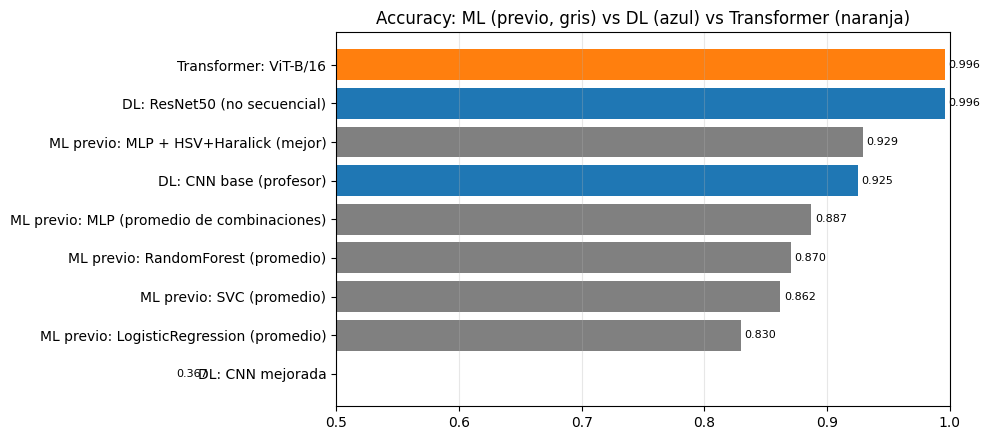

In [ ]:
colors = df_comp['Grupo'].map({'ML (práctica anterior)': 'gray', 'DL': 'tab:blue', 'Transformer': 'tab:orange'}).fillna('tab:green')
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(df_comp['Modelo'], df_comp['Accuracy'], color=colors); ax.invert_yaxis(); ax.set_xlim(0.5, 1.0)
ax.set_title('Accuracy: ML (previo, gris) vs DL (azul) vs Transformer (naranja)'); ax.grid(axis='x', alpha=.3)
for i, v in enumerate(df_comp['Accuracy']): ax.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=8)
save_fig('comparacion_barras')

### 5.2 Reporte por clase

In [ ]:
for n, r in RESULTS.items():
    print('=' * 70); print(n); print('=' * 70)
    print(classification_report(y_test, r['y_pred'], target_names=CLASSES, digits=4))

DL: CNN base (profesor)
              precision    recall  f1-score   support

       coast     0.9405    0.8778    0.9080        90
      forest     0.9535    1.0000    0.9762        82
     highway     0.8714    0.8971    0.8841        68

    accuracy                         0.9250       240
   macro avg     0.9218    0.9249    0.9228       240
weighted avg     0.9254    0.9250    0.9245       240

DL: CNN mejorada
              precision    recall  f1-score   support

       coast     0.3697    0.9778    0.5366        90
      forest     0.0000    0.0000    0.0000        82
     highway     0.0000    0.0000    0.0000        68

    accuracy                         0.3667       240
   macro avg     0.1232    0.3259    0.1789       240
weighted avg     0.1387    0.3667    0.2012       240

DL: ResNet50 (no secuencial)
              precision    recall  f1-score   support

       coast     1.0000    0.9889    0.9944        90
      forest     0.9880    1.0000    0.9939        82
     

### 5.3 Matrices de confusión

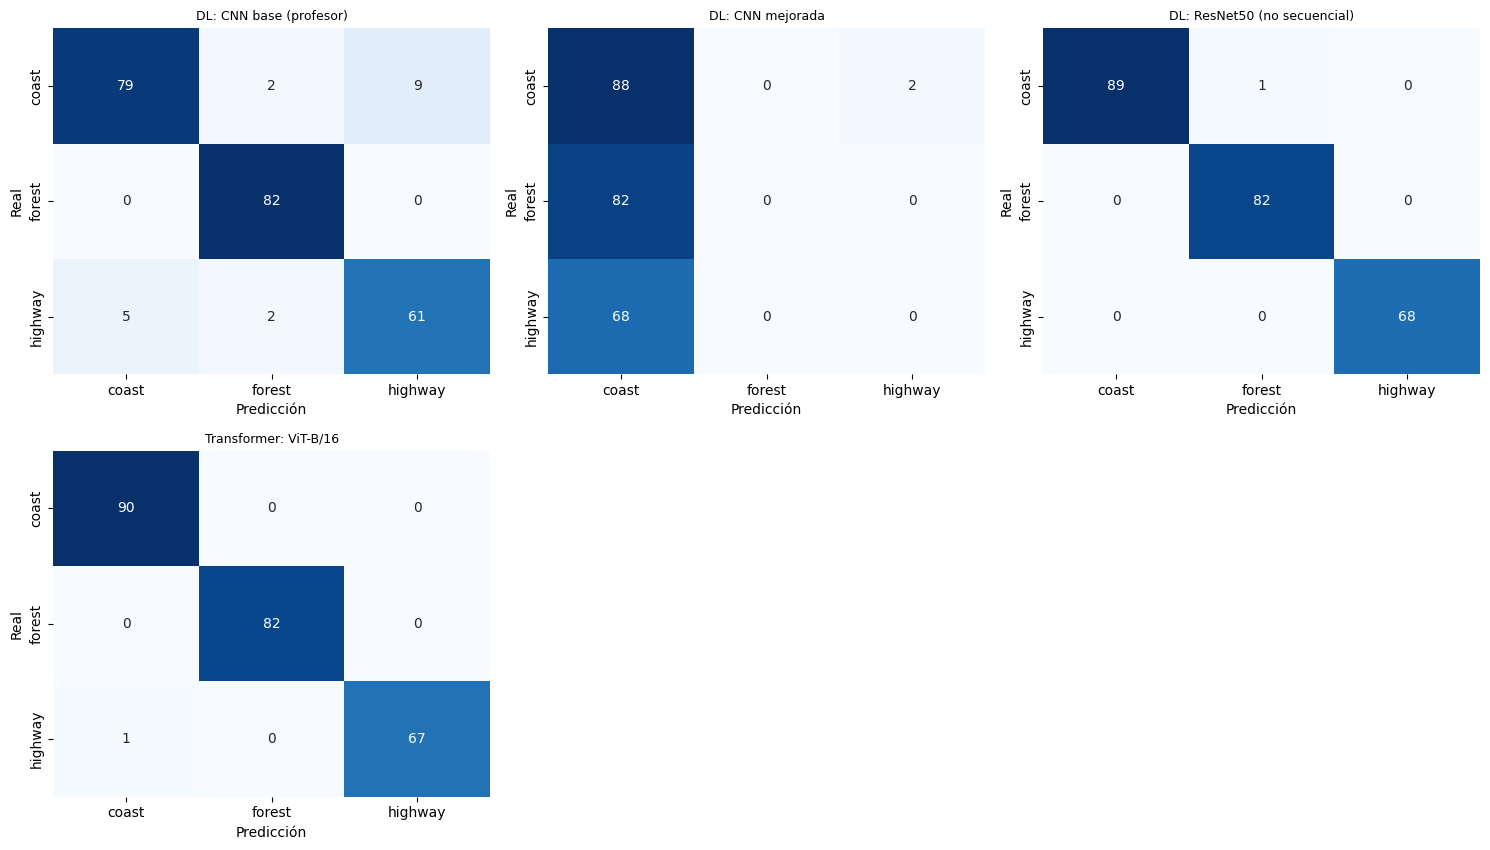

In [ ]:
n = len(RESULTS); ncols = 3; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.3 * nrows)); axes = np.array(axes).ravel()
for ax, (name, r) in zip(axes, RESULTS.items()):
    cm = confusion_matrix(y_test, r['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=CLASSES, yticklabels=CLASSES)
    ax.set_title(name, fontsize=9); ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
for ax in axes[n:]: ax.axis('off')
save_fig('matrices_confusion')

### 5.4 Curvas de entrenamiento (loss y accuracy: train vs validación)

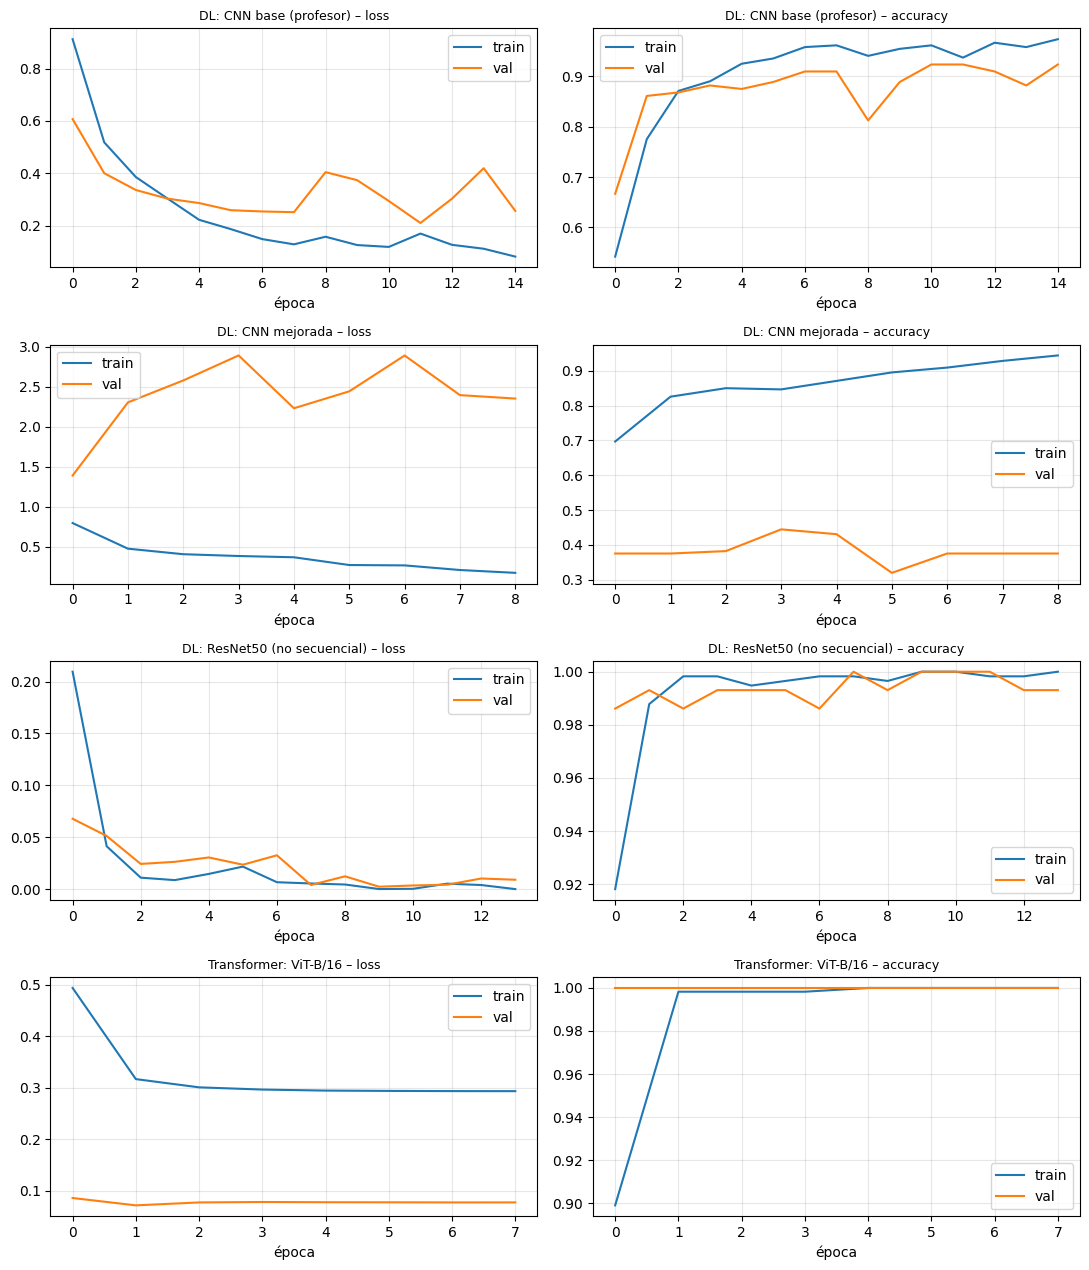

In [ ]:
hist_models = {n: r['history'] for n, r in RESULTS.items() if r['history']}
fig, axes = plt.subplots(len(hist_models), 2, figsize=(11, 3.2 * len(hist_models))); axes = np.atleast_2d(axes)
for (name, h), (a1, a2) in zip(hist_models.items(), axes):
    a1.plot(h['loss'], label='train'); a1.plot(h['val_loss'], label='val'); a1.set_title(name + ' – loss', fontsize=9); a1.legend()
    a2.plot(h['accuracy'], label='train'); a2.plot(h['val_accuracy'], label='val'); a2.set_title(name + ' – accuracy', fontsize=9); a2.legend()
    for a in (a1, a2): a.set_xlabel('época'); a.grid(alpha=.3)
save_fig('curvas_entrenamiento')

### 5.5 Curvas ROC (uno contra todos)

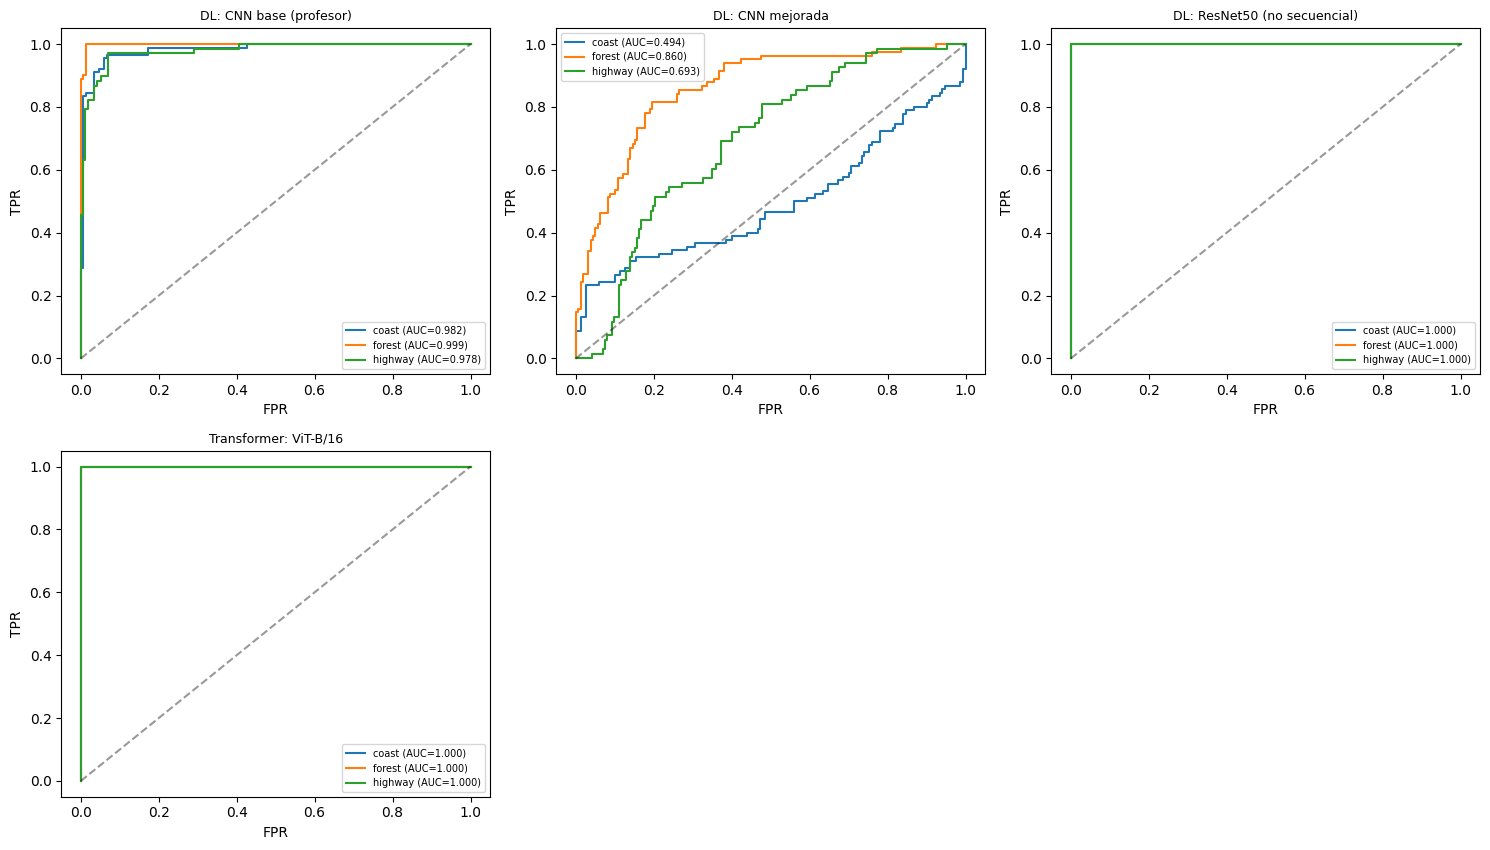

In [ ]:
Y_bin = label_binarize(y_test, classes=[0, 1, 2])
n = len(RESULTS); ncols = 3; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.3 * nrows)); axes = np.array(axes).ravel()
for ax, (name, r) in zip(axes, RESULTS.items()):
    for i, c in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(Y_bin[:, i], r['proba'][:, i]); ax.plot(fpr, tpr, label=f'{c} (AUC={auc(fpr, tpr):.3f})')
    ax.plot([0, 1], [0, 1], 'k--', alpha=.4); ax.set_title(name, fontsize=9); ax.legend(fontsize=7); ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
for ax in axes[n:]: ax.axis('off')
save_fig('curvas_roc')

### 5.6 Significancia estadística
Con un conjunto de test pequeño, una diferencia de 1–2 imágenes puede ser ruido. Se calculan:
- **Intervalo de confianza del 95 % (bootstrap)** del accuracy.
- **Test de McNemar exacto** entre pares de modelos (p < 0.05 ⇒ diferencia significativa).

,Modelo,Accuracy,IC95_inf,IC95_sup
3,Transformer: ViT-B/16,0.9958,0.9875,1.0000
2,DL: ResNet50 (no secuencial),0.9958,0.9875,1.0000
0,DL: CNN base (profesor),0.9250,0.8917,0.9543
1,DL: CNN mejorada,0.3667,0.3083,0.4293


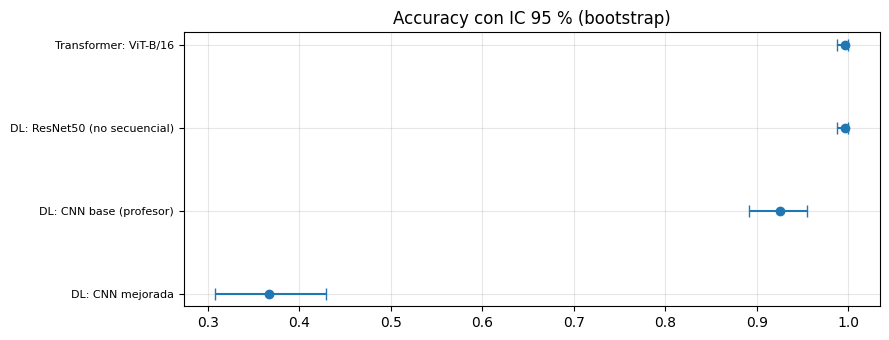

Mejor ML previo = 0.9292
  Transformer: ViT-B/16               acc=0.9958  IC95=[0.988, 1.000] -> supera claramente al ML previo
  DL: ResNet50 (no secuencial)        acc=0.9958  IC95=[0.988, 1.000] -> supera claramente al ML previo
  DL: CNN base (profesor)             acc=0.9250  IC95=[0.892, 0.954] -> ML previo cae DENTRO de su IC (diferencia no concluyente)
  DL: CNN mejorada                    acc=0.3667  IC95=[0.308, 0.429] -> por debajo del ML previo


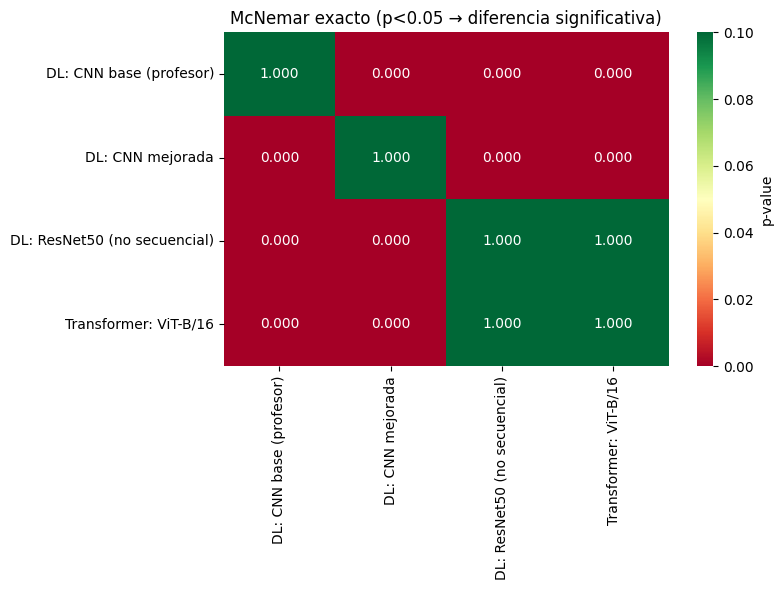

In [ ]:
from scipy.stats import binomtest
rng = np.random.default_rng(SEED)

def boot_ci(y_true, y_pred, B=2000):
    n = len(y_true); correct = (y_true == y_pred).astype(float)
    accs = [correct[rng.integers(0, n, n)].mean() for _ in range(B)]
    return np.percentile(accs, [2.5, 97.5])

ci = {n: boot_ci(y_test, r['y_pred']) for n, r in RESULTS.items()}
df_ci = pd.DataFrame({'Modelo': list(ci), 'Accuracy': [RESULTS[n]['metrics']['Accuracy'] for n in ci],
                      'IC95_inf': [v[0] for v in ci.values()], 'IC95_sup': [v[1] for v in ci.values()]}).sort_values('Accuracy', ascending=False)
display(df_ci.round(4))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.errorbar(df_ci['Accuracy'], range(len(df_ci)), xerr=[df_ci['Accuracy'] - df_ci['IC95_inf'], df_ci['IC95_sup'] - df_ci['Accuracy']], fmt='o', capsize=4)
ax.set_yticks(range(len(df_ci))); ax.set_yticklabels(df_ci['Modelo'], fontsize=8); ax.invert_yaxis(); ax.set_title('Accuracy con IC 95 % (bootstrap)'); ax.grid(alpha=.3)
save_fig('ic_bootstrap')

print(f'Mejor ML previo = {BEST_ML_ACC:.4f}')
for _, row in df_ci.iterrows():
    if row['Accuracy'] > BEST_ML_ACC and row['IC95_inf'] > BEST_ML_ACC: v = 'supera claramente al ML previo'
    elif row['IC95_inf'] <= BEST_ML_ACC <= row['IC95_sup']: v = 'ML previo cae DENTRO de su IC (diferencia no concluyente)'
    elif row['Accuracy'] < BEST_ML_ACC: v = 'por debajo del ML previo'
    else: v = 'supera al ML previo'
    print(f"  {row['Modelo']:35s} acc={row['Accuracy']:.4f}  IC95=[{row['IC95_inf']:.3f}, {row['IC95_sup']:.3f}] -> {v}")

def mcnemar_p(a, b):
    ca, cb = RESULTS[a]['y_pred'] == y_test, RESULTS[b]['y_pred'] == y_test
    b01, b10 = int((ca & ~cb).sum()), int((~ca & cb).sum()); n = b01 + b10
    return 1.0 if n == 0 else binomtest(b01, n, 0.5).pvalue

names = list(RESULTS)
P = pd.DataFrame([[mcnemar_p(a, b) for b in names] for a in names], index=names, columns=names)
plt.figure(figsize=(8, 6)); sns.heatmap(P, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0, vmax=0.1, cbar_kws={'label': 'p-value'})
plt.title('McNemar exacto (p<0.05 → diferencia significativa)'); save_fig('mcnemar')

### 5.7 Costo computacional

In [ ]:
display(df_res[['Modelo', 'Params', 'Train_s', 'Infer_ms_img', 'Accuracy']].round(4))

,Modelo,Params,Train_s,Infer_ms_img,Accuracy
0,Transformer: ViT-B/16,85800963,11800.2017,774.4225,0.9958
1,DL: ResNet50 (no secuencial),24113027,2889.7602,225.8799,0.9958
2,DL: CNN base (profesor),404899,274.4309,7.1747,0.9250
3,DL: CNN mejorada,1208419,1188.1390,45.7806,0.3667


## 6. Guardar evidencia

In [ ]:
df_comp.to_csv(OUT_DIR + 'resultados_comparativos.csv', index=False)
df_ci.to_csv(OUT_DIR + 'intervalos_confianza.csv', index=False)
P.to_csv(OUT_DIR + 'mcnemar_pvalues.csv')
pd.DataFrame({'path': paths[idx_test], 'real': [CLASSES[i] for i in y_test],
              **{n: [CLASSES[i] for i in r['y_pred']] for n, r in RESULTS.items()}}).to_csv(OUT_DIR + 'predicciones_test.csv', index=False)
json.dump({'train': idx_train.tolist(), 'val': idx_val.tolist(), 'test': idx_test.tolist(), 'seed': SEED},
          open(OUT_DIR + 'particion.json', 'w'))
torch.save(vit.state_dict(), OUT_DIR + 'modelos/vit_b16.pt')
# (los modelos CNN y ResNet50 ya se guardaron al terminar su entrenamiento, para liberar memoria)
print('Evidencia guardada en:', OUT_DIR); print(os.listdir(OUT_DIR))

Evidencia guardada en: /content/drive/MyDrive/VisionComputadorIA/Reto1_evidencia/
['figs', 'modelos', 'resultados_comparativos.csv', 'intervalos_confianza.csv', 'mcnemar_pvalues.csv', 'predicciones_test.csv', 'particion.json']


## 7. Conclusiones
1. Resultados generales. En el conjunto de test (240 imágenes) los mejores modelos fueron ResNet50 y ViT-B/16, ambos con 99.58 % de accuracy (F1-macro de 0.996), con un solo error cada uno. Les sigue la CNN base del profesor con 92.50 %. El mejor modelo de machine learning de la práctica anterior (MLP con HSV+Haralick) alcanzó 92.92 %, y los promedios del ML previo estuvieron entre 83 % y 89 %.

2. Machine learning frente a deep learning. La CNN base (92.5 %) quedó prácticamente empatada con el mejor ML previo (92.92 %), y esa última cifra cae dentro del intervalo de confianza de la CNN, así que la diferencia no es concluyente. Las características diseñadas a mano (color y textura) ya capturan buena parte de lo que distingue las tres escenas, y una CNN pequeña entrenada desde cero no mejora ese rendimiento con tan pocas imágenes. En cambio, ResNet50 y ViT superan claramente al ML previo, porque su intervalo inferior (98.8 %) queda muy por encima de 92.92 %. Como el split del ML previo fue distinto, esta comparación es indicativa y no una prueba pareada.

3. Modificación de la CNN secuencial. Al agregar doble convolución, BatchNorm, Dropout y augmentation, no se obtuvo mejora: el modelo falló en evaluación (36.7 %). Esto muestra que más capas y más regularización no garantizan mejores resultados, y que un modelo que aprende en entrenamiento puede comportarse mal en validación cuando hay capas como BatchNorm de por medio. La mejora real del reto vino de la arquitectura no secuencial y del transfer learning, no de agrandar la CNN secuencial.

4. Arquitectura no secuencial (ResNet50). Pasó de 92.5 % (CNN base) a 99.58 %. Las conexiones residuales permiten entrenar una red profunda sin que se degrade el gradiente, y los pesos preentrenados en ImageNet ya traen filtros útiles para bordes, texturas y formas. Esto se nota en las curvas: ya en la primera época tenía 98.6 % de validación, mientras que la CNN base necesitó casi 12 épocas para acercarse a 92 %. Parte de esta ventaja se debe al preentrenamiento y no solo a la arquitectura.

5. Transformer (ViT). Igualó a ResNet50 (99.58 %) a pesar de ser un modelo muy distinto: se basa en self-attention sobre parches de 16×16 en lugar de convoluciones. Sus errores y los de ResNet50 son uno cada uno y sobre imágenes distintas (ResNet50 falló en una coast, ViT en una highway), por lo que la diferencia entre ambos no es estadísticamente significativa. Con un dataset de solo 958 imágenes, el ViT depende casi por completo del preentrenamiento; entrenado desde cero rendiría mucho peor, porque carece del sesgo inductivo de las convoluciones.

6. Costo computacional. La ejecución se hizo en CPU, así que los tiempos son altos, pero la proporción es informativa: la CNN base entrenó en ~4.6 min y clasificó a 7 ms por imagen; ResNet50 tardó ~48 min y 226 ms por imagen; el ViT tardó ~3.3 h y 774 ms por imagen, con 86 millones de parámetros frente a 24 millones de ResNet50 y 0.4 millones de la CNN base. Por unos 7 puntos de accuracy más, el costo se multiplica por más de 10 al pasar de la CNN base a ResNet50, y el ViT no ofrece ganancia adicional frente a ResNet50, solo más costo.

7. Validación. Las métricas por clase muestran que highway y forest se reconocen casi perfectamente en los modelos preentrenados, y que la CNN base confunde sobre todo coast y highway (F1 de 0.91 y 0.88). El intervalo de confianza por bootstrap y el valor Kappa/MCC confirman que el resultado de ResNet50 y ViT no es producto del azar. El test de McNemar indica que no hay diferencia significativa entre ellos.

8. Limitaciones. (a) Un solo split de 960 imágenes: con 240 de test, un error más o menos mueve el accuracy 0.4 puntos, así que 99.58 % vs 100 % no es una diferencia real. (b) La validación llegó a 100 % desde la primera época en el ViT, lo que indica que el problema es fácil para modelos preentrenados y que la validación casi no sirvió para distinguir épocas. (c) La comparación con el ML previo usa otro split. (d) La CNN mejorada necesita ser corregida y repetida.

Conclusión final. Para esta tarea, el machine learning clásico con características de color y textura ya ofrece un resultado respetable (~93 %) a un costo mínimo. El deep learning sin preentrenamiento no lo supera con tan pocos datos. El mayor salto (a ~99.6 %) llega con modelos preentrenados, ya sea convolucional con conexiones residuales (ResNet50) o Transformer (ViT). Entre ellos, ResNet50 es la mejor opción práctica: iguala la precisión del ViT con una cuarta parte del costo.